# Project 4: Next-Word Prediction Using Word Embeddings and a Neural Language Model

## Objective

The objective of this project is to build a neural language model that predicts the next word in a sequence of text. The project demonstrates the complete natural language processing pipeline, including text collection, preprocessing, tokenization, vocabulary construction, training-sequence generation, Word2Vec embedding generation, neural-network training, and model evaluation.

The model will use a fixed number of previous words as context and predict the most likely next word. Word2Vec will be used to convert words into dense numerical vectors, and a feedforward neural network implemented in PyTorch will learn the relationship between the context words and the target next word.

In [1]:
# Standard libraries
import re
import string
import random
from collections import Counter

# Data handling and numerical operations
import numpy as np

# Word embeddings
from gensim.models import Word2Vec

# Deep learning
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

# Visualization
import matplotlib.pyplot as plt

# Reproducibility
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

print("PyTorch version:", torch.__version__)
print("Libraries imported successfully.")

PyTorch version: 2.10.0+cpu
Libraries imported successfully.


In [2]:
# Import NLTK and Gutenberg corpus
import nltk
from nltk.corpus import gutenberg

# Download the Gutenberg corpus if it is not already installed
try:
    gutenberg.fileids()
except LookupError:
    nltk.download("gutenberg")

# Load Jane Austen's Emma
raw_text = gutenberg.raw("austen-emma.txt")

print("Dataset loaded successfully.")
print("Total characters:", len(raw_text))
print("\nFirst 500 characters:\n")
print(raw_text[:500])

Dataset loaded successfully.
Total characters: 887071

First 500 characters:

[Emma by Jane Austen 1816]

VOLUME I

CHAPTER I


Emma Woodhouse, handsome, clever, and rich, with a comfortable home
and happy disposition, seemed to unite some of the best blessings
of existence; and had lived nearly twenty-one years in the world
with very little to distress or vex her.

She was the youngest of the two daughters of a most affectionate,
indulgent father; and had, in consequence of her sister's marriage,
been mistress of his house from a very early period.  Her mother
had died t


## Dataset Collection

For this project, the text of *Emma* by Jane Austen was obtained from the NLTK Gutenberg corpus. The Gutenberg corpus contains publicly available literary texts and provides a convenient source of continuous natural-language data for language-modeling experiments.

The raw dataset contains approximately 887,000 characters. At this stage, the text contains uppercase and lowercase letters, punctuation, chapter headings, and other formatting. These elements will be processed in the following steps before the text is used to train the language model.

A continuous text corpus is appropriate for next-word prediction because the model needs to learn relationships between words based on the order in which they occur.

In [3]:
# Convert text to lowercase
clean_text = raw_text.lower()

# Remove extra whitespace such as repeated spaces, tabs, and newlines
clean_text = re.sub(r"\s+", " ", clean_text).strip()

print("Text converted to lowercase and extra whitespace removed.")
print("Total characters after basic cleaning:", len(clean_text))
print("\nFirst 500 characters:\n")
print(clean_text[:500])

Text converted to lowercase and extra whitespace removed.
Total characters after basic cleaning: 880781

First 500 characters:

[emma by jane austen 1816] volume i chapter i emma woodhouse, handsome, clever, and rich, with a comfortable home and happy disposition, seemed to unite some of the best blessings of existence; and had lived nearly twenty-one years in the world with very little to distress or vex her. she was the youngest of the two daughters of a most affectionate, indulgent father; and had, in consequence of her sister's marriage, been mistress of his house from a very early period. her mother had died too lon


In [4]:
# Replace punctuation marks with spaces
no_punct_text = clean_text.translate(
    str.maketrans(string.punctuation, " " * len(string.punctuation))
)

# Remove any extra spaces created by punctuation removal
no_punct_text = re.sub(r"\s+", " ", no_punct_text).strip()

print("Punctuation removed successfully.")
print("Total characters after punctuation removal:", len(no_punct_text))
print("\nFirst 500 characters:\n")
print(no_punct_text[:500])

Punctuation removed successfully.
Total characters after punctuation removal: 846332

First 500 characters:

emma by jane austen 1816 volume i chapter i emma woodhouse handsome clever and rich with a comfortable home and happy disposition seemed to unite some of the best blessings of existence and had lived nearly twenty one years in the world with very little to distress or vex her she was the youngest of the two daughters of a most affectionate indulgent father and had in consequence of her sister s marriage been mistress of his house from a very early period her mother had died too long ago for her 


In [5]:
# Tokenize the cleaned text by splitting on whitespace
tokens = no_punct_text.split()

print("Tokenization completed successfully.")
print("Total tokens:", len(tokens))
print("\nFirst 50 tokens:\n")
print(tokens[:50])

Tokenization completed successfully.
Total tokens: 161980

First 50 tokens:

['emma', 'by', 'jane', 'austen', '1816', 'volume', 'i', 'chapter', 'i', 'emma', 'woodhouse', 'handsome', 'clever', 'and', 'rich', 'with', 'a', 'comfortable', 'home', 'and', 'happy', 'disposition', 'seemed', 'to', 'unite', 'some', 'of', 'the', 'best', 'blessings', 'of', 'existence', 'and', 'had', 'lived', 'nearly', 'twenty', 'one', 'years', 'in', 'the', 'world', 'with', 'very', 'little', 'to', 'distress', 'or', 'vex', 'her']


In [6]:
# Count the frequency of every token
word_counts = Counter(tokens)

# Keep words that appear at least twice
min_frequency = 2

vocab_words = sorted([
    word for word, count in word_counts.items()
    if count >= min_frequency
])

# Add a special token for rare/unknown words
vocab = ["<UNK>"] + vocab_words

# Create word-to-index and index-to-word mappings
word_to_idx = {word: idx for idx, word in enumerate(vocab)}
idx_to_word = {idx: word for word, idx in word_to_idx.items()}

print("Vocabulary construction completed.")
print("Total unique tokens before filtering:", len(word_counts))
print("Vocabulary size after filtering:", len(vocab))
print("Words occurring only once:",
      sum(1 for count in word_counts.values() if count == 1))

print("\nFirst 20 vocabulary entries:")
print(vocab[:20])

print("\nMost common 10 words:")
print(word_counts.most_common(10))

Vocabulary construction completed.
Total unique tokens before filtering: 7103
Vocabulary size after filtering: 4348
Words occurring only once: 2756

First 20 vocabulary entries:
['<UNK>', '000', '10', '28th', 'a', 'abbey', 'abilities', 'able', 'abominable', 'about', 'above', 'abroad', 'abrupt', 'abruptly', 'absence', 'absent', 'absenting', 'absolute', 'absolutely', 'absurdity']

Most common 10 words:
[('to', 5242), ('the', 5204), ('and', 4897), ('of', 4293), ('i', 3192), ('a', 3130), ('it', 2529), ('her', 2490), ('was', 2400), ('she', 2364)]


## Generating Training Sequences

A next-word prediction model learns from examples consisting of a sequence of context words and the word that immediately follows them.

In this project, a context length of three words is used. For example, if the cleaned text contains:

`emma was very happy today`

the training examples would include:

- Input: `emma was very` → Target: `happy`
- Input: `was very happy` → Target: `today`

Each input therefore contains three consecutive words, while the target contains the next word in the text.

Words that occur fewer than two times in the corpus are represented using the special `<UNK>` token. This reduces the vocabulary size and allows rare words to be handled consistently.

The generated context-target pairs will later be converted into numerical representations and used to train the neural language model.

In [7]:
# Replace rare words with <UNK>
processed_tokens = [
    token if word_counts[token] >= min_frequency else "<UNK>"
    for token in tokens
]

# Number of previous words used to predict the next word
context_size = 3

# Store input sequences and target words
contexts = []
targets = []

for i in range(len(processed_tokens) - context_size):
    context_words = processed_tokens[i:i + context_size]
    target_word = processed_tokens[i + context_size]

    # Convert words to vocabulary indices
    context_indices = [word_to_idx[word] for word in context_words]
    target_index = word_to_idx[target_word]

    contexts.append(context_indices)
    targets.append(target_index)

# Convert to NumPy arrays
contexts = np.array(contexts, dtype=np.int64)
targets = np.array(targets, dtype=np.int64)

print("Training sequences generated successfully.")
print("Number of context-target pairs:", len(contexts))
print("Context array shape:", contexts.shape)
print("Target array shape:", targets.shape)

print("\nFirst 5 training examples:\n")

for i in range(5):
    context_words = [idx_to_word[idx] for idx in contexts[i]]
    target_word = idx_to_word[targets[i]]

    print(f"Input: {' '.join(context_words):30s} -> Target: {target_word}")

Training sequences generated successfully.
Number of context-target pairs: 161977
Context array shape: (161977, 3)
Target array shape: (161977,)

First 5 training examples:

Input: emma by jane                   -> Target: <UNK>
Input: by jane <UNK>                  -> Target: <UNK>
Input: jane <UNK> <UNK>               -> Target: volume
Input: <UNK> <UNK> volume             -> Target: i
Input: <UNK> volume i                 -> Target: chapter


In [8]:
# Prepare the corpus for Word2Vec
# Split the token list into manageable chunks for Word2Vec training
chunk_size = 1000

word2vec_sentences = [
    processed_tokens[i:i + chunk_size]
    for i in range(0, len(processed_tokens), chunk_size)
]

# Train the Word2Vec model
word2vec_model = Word2Vec(
    sentences=word2vec_sentences,
    vector_size=100,
    window=5,
    min_count=1,
    workers=1,
    sg=1,
    epochs=10,
    seed=42
)

print("Word2Vec training completed successfully.")
print("Embedding dimension:", word2vec_model.vector_size)
print("Words in Word2Vec vocabulary:", len(word2vec_model.wv))

# Display the first 10 values of the vector for a sample word
sample_word = "emma"

print(f"\nFirst 10 values of the embedding for '{sample_word}':")
print(word2vec_model.wv[sample_word][:10])

Word2Vec training completed successfully.
Embedding dimension: 100
Words in Word2Vec vocabulary: 4348

First 10 values of the embedding for 'emma':
[ 0.08855519  0.33067548 -0.00487942  0.320225   -0.22840194 -0.04277633
  0.26281965  0.14816488 -0.20012464  0.06646714]


In [9]:
# Inspect several learned word embeddings
sample_words = ["emma", "father", "house", "happy"]

for word in sample_words:
    if word in word2vec_model.wv:
        vector = word2vec_model.wv[word]

        print(f"Word: {word}")
        print(f"Vector shape: {vector.shape}")
        print(f"First 5 values: {vector[:5]}")
        print()

# Find words with embeddings most similar to "emma"
print("Words most similar to 'emma':\n")

similar_words = word2vec_model.wv.most_similar("emma", topn=5)

for word, similarity in similar_words:
    print(f"{word:15s} similarity = {similarity:.4f}")

Word: emma
Vector shape: (100,)
First 5 values: [ 0.08855519  0.33067548 -0.00487942  0.320225   -0.22840194]

Word: father
Vector shape: (100,)
First 5 values: [ 0.09350323  0.05123955  0.12618104  0.06371903 -0.12271894]

Word: house
Vector shape: (100,)
First 5 values: [-0.04520426 -0.04579428 -0.3828164  -0.04336172  0.15270111]

Word: happy
Vector shape: (100,)
First 5 values: [ 0.10221665  0.53102154  0.01097848  0.20955002 -0.09206372]

Words most similar to 'emma':

harriet         similarity = 0.7073
cheeks          similarity = 0.6651
eagerly         similarity = 0.6622
pause           similarity = 0.6456
tears           similarity = 0.6453


In [10]:
# Create an embedding matrix using the trained Word2Vec vectors
embedding_dim = word2vec_model.vector_size
vocab_size = len(vocab)

embedding_matrix = np.zeros(
    (vocab_size, embedding_dim),
    dtype=np.float32
)

# Place each word's Word2Vec vector at its vocabulary index
for word, idx in word_to_idx.items():
    embedding_matrix[idx] = word2vec_model.wv[word]

print("Embedding matrix created successfully.")
print("Vocabulary size:", vocab_size)
print("Embedding dimension:", embedding_dim)
print("Embedding matrix shape:", embedding_matrix.shape)

# Verify the embedding for a sample word
sample_word = "emma"
sample_idx = word_to_idx[sample_word]

print(f"\nVocabulary index for '{sample_word}':", sample_idx)
print(
    f"Embedding shape for '{sample_word}':",
    embedding_matrix[sample_idx].shape
)
print(f"First 10 values for '{sample_word}':")
print(embedding_matrix[sample_idx][:10])

Embedding matrix created successfully.
Vocabulary size: 4348
Embedding dimension: 100
Embedding matrix shape: (4348, 100)

Vocabulary index for 'emma': 1295
Embedding shape for 'emma': (100,)
First 10 values for 'emma':
[ 0.08855519  0.33067548 -0.00487942  0.320225   -0.22840194 -0.04277633
  0.26281965  0.14816488 -0.20012464  0.06646714]


In [11]:
# Create a custom PyTorch Dataset
class NextWordDataset(Dataset):
    def __init__(self, contexts, targets):
        self.contexts = torch.tensor(contexts, dtype=torch.long)
        self.targets = torch.tensor(targets, dtype=torch.long)

    def __len__(self):
        return len(self.contexts)

    def __getitem__(self, idx):
        return self.contexts[idx], self.targets[idx]


# Create the dataset
dataset = NextWordDataset(contexts, targets)

# Create a DataLoader for mini-batch training
batch_size = 256

data_loader = DataLoader(
    dataset,
    batch_size=batch_size,
    shuffle=True
)

print("PyTorch Dataset and DataLoader created successfully.")
print("Total training examples:", len(dataset))
print("Batch size:", batch_size)
print("Number of batches:", len(data_loader))

# Inspect one batch
context_batch, target_batch = next(iter(data_loader))

print("\nContext batch shape:", context_batch.shape)
print("Target batch shape:", target_batch.shape)

print("\nFirst context in the batch:")
print(context_batch[0])

print("Corresponding words:")
print([idx_to_word[idx.item()] for idx in context_batch[0]])

print("Target word:")
print(idx_to_word[target_batch[0].item()])

PyTorch Dataset and DataLoader created successfully.
Total training examples: 161977
Batch size: 256
Number of batches: 633

Context batch shape: torch.Size([256, 3])
Target batch shape: torch.Size([256])

First context in the batch:
tensor([ 200, 3889, 2122])
Corresponding words:
['and', 'the', 'intention']
Target word:
of


In [12]:
# Define the neural language model
class NeuralLanguageModel(nn.Module):
    def __init__(self, vocab_size, embedding_dim, context_size, embedding_matrix):
        super().__init__()

        # Embedding layer initialized with the trained Word2Vec vectors
        self.embedding = nn.Embedding.from_pretrained(
            torch.tensor(embedding_matrix, dtype=torch.float32),
            freeze=True
        )

        # The three 100-dimensional embeddings will be concatenated
        input_size = embedding_dim * context_size

        # Feedforward neural network
        self.fc1 = nn.Linear(input_size, 128)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(0.3)
        self.fc2 = nn.Linear(128, vocab_size)

    def forward(self, x):
        # x shape: (batch_size, context_size)
        x = self.embedding(x)

        # x shape: (batch_size, context_size, embedding_dim)
        x = x.view(x.size(0), -1)

        # x shape: (batch_size, context_size * embedding_dim)
        x = self.fc1(x)
        x = self.relu(x)
        x = self.dropout(x)

        # Output one score for every word in the vocabulary
        x = self.fc2(x)

        return x


# Create the model
model = NeuralLanguageModel(
    vocab_size=vocab_size,
    embedding_dim=embedding_dim,
    context_size=context_size,
    embedding_matrix=embedding_matrix
)

print(model)

# Test the model using one batch
sample_output = model(context_batch)

print("\nInput batch shape:", context_batch.shape)
print("Model output shape:", sample_output.shape)

NeuralLanguageModel(
  (embedding): Embedding(4348, 100)
  (fc1): Linear(in_features=300, out_features=128, bias=True)
  (relu): ReLU()
  (dropout): Dropout(p=0.3, inplace=False)
  (fc2): Linear(in_features=128, out_features=4348, bias=True)
)

Input batch shape: torch.Size([256, 3])
Model output shape: torch.Size([256, 4348])


In [13]:
# Split the context-target pairs into training and validation sets
split_index = int(0.90 * len(contexts))

train_contexts = contexts[:split_index]
train_targets = targets[:split_index]

val_contexts = contexts[split_index:]
val_targets = targets[split_index:]

# Create PyTorch datasets
train_dataset = NextWordDataset(train_contexts, train_targets)
val_dataset = NextWordDataset(val_contexts, val_targets)

# Create DataLoaders
batch_size = 256

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False
)

print("Training and validation datasets created successfully.")

print("\nTraining examples:", len(train_dataset))
print("Validation examples:", len(val_dataset))

print("\nTraining batches:", len(train_loader))
print("Validation batches:", len(val_loader))

print("\nTraining percentage:",
      round(len(train_dataset) / len(dataset) * 100, 2), "%")

print("Validation percentage:",
      round(len(val_dataset) / len(dataset) * 100, 2), "%")

Training and validation datasets created successfully.

Training examples: 145779
Validation examples: 16198

Training batches: 570
Validation batches: 64

Training percentage: 90.0 %
Validation percentage: 10.0 %


In [14]:
# Define the loss function and optimizer
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

# Number of training epochs
num_epochs = 5

# Store metrics for later visualization
train_losses = []
val_losses = []
val_accuracies = []

for epoch in range(num_epochs):

    # -------------------------
    # Training
    # -------------------------
    model.train()

    total_train_loss = 0.0

    for context_batch, target_batch in train_loader:

        # Clear gradients from the previous batch
        optimizer.zero_grad()

        # Forward pass
        outputs = model(context_batch)

        # Calculate loss
        loss = criterion(outputs, target_batch)

        # Backpropagation
        loss.backward()

        # Update model weights
        optimizer.step()

        total_train_loss += loss.item()

    average_train_loss = total_train_loss / len(train_loader)
    train_losses.append(average_train_loss)

    # -------------------------
    # Validation
    # -------------------------
    model.eval()

    total_val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for context_batch, target_batch in val_loader:

            outputs = model(context_batch)

            loss = criterion(outputs, target_batch)
            total_val_loss += loss.item()

            # Select the word with the highest predicted score
            predictions = torch.argmax(outputs, dim=1)

            correct += (predictions == target_batch).sum().item()
            total += target_batch.size(0)

    average_val_loss = total_val_loss / len(val_loader)
    val_accuracy = correct / total

    val_losses.append(average_val_loss)
    val_accuracies.append(val_accuracy)

    print(
        f"Epoch {epoch + 1}/{num_epochs} | "
        f"Train Loss: {average_train_loss:.4f} | "
        f"Validation Loss: {average_val_loss:.4f} | "
        f"Validation Accuracy: {val_accuracy:.4f}"
    )

print("\nNeural network training completed.")

Epoch 1/5 | Train Loss: 5.8905 | Validation Loss: 5.4460 | Validation Accuracy: 0.1170
Epoch 2/5 | Train Loss: 5.3154 | Validation Loss: 5.2494 | Validation Accuracy: 0.1269
Epoch 3/5 | Train Loss: 5.1336 | Validation Loss: 5.1562 | Validation Accuracy: 0.1290
Epoch 4/5 | Train Loss: 5.0139 | Validation Loss: 5.1104 | Validation Accuracy: 0.1308
Epoch 5/5 | Train Loss: 4.9200 | Validation Loss: 5.0719 | Validation Accuracy: 0.1354

Neural network training completed.


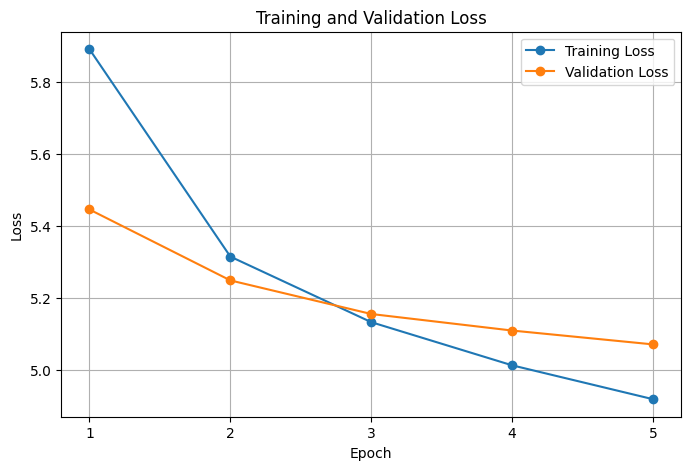

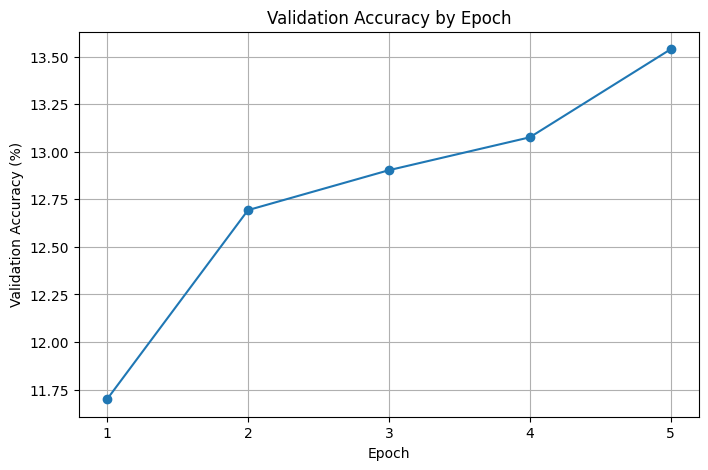

In [15]:
# Plot training and validation loss
epochs = range(1, num_epochs + 1)

plt.figure(figsize=(8, 5))

plt.plot(epochs, train_losses, marker="o", label="Training Loss")
plt.plot(epochs, val_losses, marker="o", label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.xticks(epochs)
plt.legend()
plt.grid(True)

plt.show()


# Plot validation accuracy
plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    [accuracy * 100 for accuracy in val_accuracies],
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy (%)")
plt.title("Validation Accuracy by Epoch")
plt.xticks(epochs)
plt.grid(True)

plt.show()

In [16]:
# Function to predict the next word from three context words
def predict_next_word(context_words, top_k=5):
    model.eval()

    # Convert input words to lowercase and map unknown words to <UNK>
    processed_context = [
        word.lower() if word.lower() in word_to_idx else "<UNK>"
        for word in context_words
    ]

    # Convert words to vocabulary indices
    context_indices = [
        word_to_idx[word] for word in processed_context
    ]

    # Create tensor with shape (1, context_size)
    context_tensor = torch.tensor(
        [context_indices],
        dtype=torch.long
    )

    with torch.no_grad():
        outputs = model(context_tensor)

        # Convert model scores into probabilities
        probabilities = torch.softmax(outputs, dim=1)

        # Get the top-k predictions
        top_probs, top_indices = torch.topk(
            probabilities,
            k=top_k,
            dim=1
        )

    predictions = []

    for prob, idx in zip(top_probs[0], top_indices[0]):
        predictions.append(
            (idx_to_word[idx.item()], prob.item())
        )

    return predictions


# Examine several examples from the validation set
sample_positions = [0, 500, 2000, 5000, 10000]

print("NEXT-WORD PREDICTION EXAMPLES")
print("=" * 60)

for position in sample_positions:
    context_indices = val_contexts[position]
    actual_index = val_targets[position]

    context_words = [
        idx_to_word[idx] for idx in context_indices
    ]

    actual_word = idx_to_word[actual_index]

    predictions = predict_next_word(
        context_words,
        top_k=5
    )

    print(f"\nContext: {' '.join(context_words)}")
    print(f"Actual next word: {actual_word}")

    print("Top 5 predicted words:")

    for word, probability in predictions:
        print(
            f"  {word:15s} "
            f"{probability * 100:.2f}%"
        )

NEXT-WORD PREDICTION EXAMPLES

Context: of see me
Actual next word: then
Top 5 predicted words:
  to              11.71%
  and             9.46%
  but             6.03%
  i               4.87%
  in              3.62%

Context: what you saw
Actual next word: amiss
Top 5 predicted words:
  me              6.94%
  it              6.87%
  you             6.12%
  her             5.24%
  the             5.00%

Context: i <UNK> at
Actual next word: the
Top 5 predicted words:
  all             11.72%
  the             11.00%
  least           5.37%
  hartfield       4.34%
  last            3.89%

Context: of something most
Actual next word: painful
Top 5 predicted words:
  <UNK>           2.27%
  to              2.14%
  and             2.13%
  the             1.48%
  a               1.34%

Context: that he must
Actual next word: not
Top 5 predicted words:
  be              24.54%
  have            18.38%
  not             7.13%
  say             1.89%
  come            1.78%


## Plain-English Explanation of the Complete Pipeline

### 1. Dataset Collection

The project uses *Emma* by Jane Austen from the NLTK Gutenberg corpus. The raw text contained approximately 887,000 characters and provided a continuous natural-language corpus suitable for next-word prediction.

### 2. Text Cleaning and Lowercasing

The raw text was converted entirely to lowercase so that words such as `Emma` and `emma` would be treated as the same token. Repeated spaces, tabs, and newline characters were also normalized.

### 3. Punctuation Removal

Punctuation symbols were replaced with spaces. Replacing punctuation with spaces instead of simply deleting it prevents neighboring words from accidentally being joined together. For example, `twenty-one` becomes `twenty one` rather than `twentyone`.

### 4. Tokenization

The cleaned text was split into individual word tokens. After preprocessing, the corpus contained 161,980 tokens.

### 5. Vocabulary Construction

The frequency of each token was calculated. The original corpus contained 7,103 unique tokens. Words that occurred only once were represented by the special `<UNK>` token. After filtering, the final vocabulary contained 4,348 entries.

Each vocabulary word was assigned a numerical index so that it could be processed computationally.

### 6. Training-Sequence Generation

A context window of three words was used for next-word prediction. Each training example contains three consecutive context words and the word immediately following them as the target.

For example:

`emma was very` → `happy`

Sliding this window through the corpus produced 161,977 context-target pairs.

### 7. Word2Vec Embeddings

Word2Vec was trained on the processed corpus using the Skip-gram method. Each vocabulary word was represented using a 100-dimensional dense vector. These vectors capture contextual relationships between words rather than representing words only as arbitrary numerical IDs.

For example, the trained Word2Vec model identified `harriet` as the word most similar to `emma`, with a cosine similarity of approximately 0.7073. This demonstrates that the embedding model learned contextual relationships from the novel.

The final embedding matrix had dimensions 4,348 × 100, representing 4,348 vocabulary words with 100 numerical features per word.

### 8. Neural Language Model

A feedforward neural network was implemented using PyTorch. The model receives three vocabulary indices as input. Each index is converted into its corresponding fixed 100-dimensional Word2Vec vector.

Because three context words are used, the three embeddings are concatenated to produce 300 input features:

3 context words × 100 embedding dimensions = 300 input features.

The neural network architecture consists of:

- A pretrained Word2Vec embedding layer
- A fully connected layer from 300 to 128 units
- ReLU activation
- Dropout with a rate of 0.3
- A final fully connected layer from 128 units to 4,348 vocabulary scores

The Word2Vec embeddings were kept fixed during neural-network training so that the network learned how to use the previously learned word representations.

### 9. Model Training

The context-target pairs were divided into approximately 90% training data and 10% validation data. This produced 145,779 training examples and 16,198 validation examples.

The neural network was trained for five epochs using the Adam optimizer with a learning rate of 0.001 and cross-entropy loss. Training was performed using mini-batches of 256 examples.

The training results were:

| Epoch | Training Loss | Validation Loss | Validation Accuracy |
|---|---:|---:|---:|
| 1 | 5.8905 | 5.4460 | 11.70% |
| 2 | 5.3154 | 5.2494 | 12.69% |
| 3 | 5.1336 | 5.1562 | 12.90% |
| 4 | 5.0139 | 5.1104 | 13.08% |
| 5 | 4.9200 | 5.0719 | 13.54% |

Training loss decreased from 5.8905 to 4.9200, while validation loss decreased from 5.4460 to 5.0719. Validation accuracy increased from 11.70% to 13.54%. These trends indicate that the neural network learned useful next-word relationships from the training data.

Exact next-word prediction is a difficult task because the model must select one word from 4,348 vocabulary possibilities and several words may be linguistically reasonable after the same context.

### 10. Next-Word Prediction

After training, the model was tested on validation contexts and the five most probable next words were displayed.

For example:

`i <UNK> at`

had the actual next word `the`, and the model ranked `the` as its second-most likely prediction.

For:

`that he must`

the actual next word was `not`, and the model ranked `not` among its top three predictions.

These examples demonstrate how the trained neural language model uses contextual word embeddings to assign probabilities to possible next words.

## Conclusion

This project implemented a complete next-word prediction pipeline beginning with raw text and ending with a trained neural language model. The text was cleaned, converted to lowercase, stripped of punctuation, tokenized, and transformed into a vocabulary. Context-target sequences were then generated for language-model training.

Word2Vec was used to learn 100-dimensional numerical representations of the vocabulary words. These embeddings were incorporated into a feedforward neural network that used three preceding words to predict the next word. Across five training epochs, both training and validation loss decreased while validation accuracy increased to 13.54%.

The results demonstrate the basic principles behind neural language modeling: words can be represented as learned numerical vectors, multiple word representations can provide contextual information, and a neural network can learn statistical patterns that help predict subsequent words. More advanced language models could improve performance through larger datasets, longer contexts, recurrent neural networks, LSTMs, or Transformer-based architectures.

## References

Bird, S., Klein, E., & Loper, E. (2009). *Natural language processing with Python: Analyzing text with the Natural Language Toolkit*. O'Reilly Media.

Mikolov, T., Chen, K., Corrado, G., & Dean, J. (2013). Efficient estimation of word representations in vector space. *International Conference on Learning Representations (ICLR) Workshop*. arXiv:1301.3781.

Řehůřek, R., & Sojka, P. (2010). Software framework for topic modelling with large corpora. *Proceedings of the LREC 2010 Workshop on New Challenges for NLP Frameworks*, 45–50.

PyTorch. (2026). *PyTorch documentation: CrossEntropyLoss*. PyTorch.

## AI Use Disclosure

ChatGPT (OpenAI) was used as a learning and development aid for this project. It was used to help explain concepts related to Word2Vec embeddings, next-word prediction, neural-network architecture, and to assist with organizing and reviewing the Python implementation and written explanations. The generated code was executed step by step in the local Python environment, and its outputs, tensor dimensions, vocabulary statistics, training behavior, validation metrics, and prediction examples were reviewed to verify that the implementation operated as intended. The final results reported in this submission are based on the actual outputs produced by the executed notebook. I remain responsible for the accuracy, originality, and integrity of the submitted work.